**Лабораторна робота № 5 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

Вивести інформацію про датасет

In [ ]:
df.info()
print("\nТипи: категоріальні (object) — gender, smoking_history; решта числові.")

Провести дослідження категоріальних ознак

In [ ]:
print("Частоти gender:")
print(df["gender"].value_counts(dropna=False))

In [ ]:
print("Частоти smoking_history:")
print(df["smoking_history"].value_counts(dropna=False))

In [ ]:
# TODO: Кодування категорій зробимо після поділу на train і test.

In [ ]:
display(df.head())

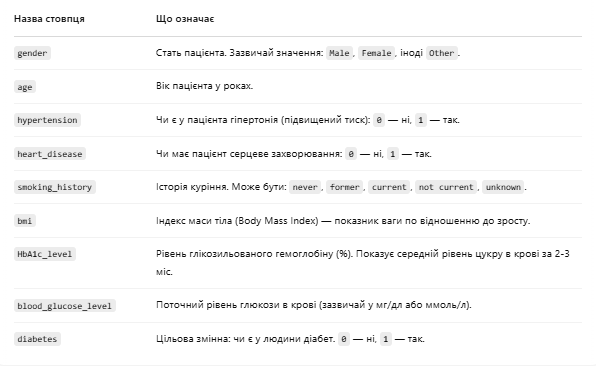

Вивести типи даних

In [ ]:
print(df.dtypes)

Дослідити цільову змінну: перевірити баланс класів

In [ ]:
print(df["diabetes"].value_counts())
print("Частки класів, %:")
print((df["diabetes"].value_counts(normalize=True) * 100).round(2))

Висновок: визначте за результатом, чи є дисбаланс класів.
**Висновок:** порівнюємо частки `diabetes=0` і `diabetes=1`, а не лише абсолютні кількості. Якщо клас 1 суттєво рідший, маємо дисбаланс; тому під час навчання застосуємо SMOTE **лише до train**. Числові значення виводяться в клітинці вище.

Перевірити наявність пропущених даних


In [ ]:
print("Пропуски по стовпцях:")
print(df.isnull().sum())

Наявність дублікатів


In [ ]:
print("Кількість повністю однакових рядків:", df.duplicated().sum())

Видалити дублікати

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
print("Рядків після видалення дублікатів:", len(df))

In [ ]:
display(df.head())

Ще раз перевірити баланс цільової змінної

In [ ]:
print("Баланс після видалення дублікатів:")
print(df["diabetes"].value_counts())
print((df["diabetes"].value_counts(normalize=True) * 100).round(2))

Побудувати гістограму для цільової змінної


In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="diabetes", color="tab:blue")
plt.title("Розподіл цільової змінної")
plt.xlabel("diabetes (0 — ні, 1 — так)")
plt.ylabel("Кількість")
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
X = df.drop(columns="diabetes")
y = df["diabetes"]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print("Розміри train/test:", X_train_raw.shape, X_test_raw.shape)
print("Частки класів у train:", y_train.value_counts(normalize=True).round(4).to_dict())
print("Частки класів у test:", y_test.value_counts(normalize=True).round(4).to_dict())

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
categorical_cols = ["gender", "smoking_history"]
X_train = pd.get_dummies(X_train_raw, columns=categorical_cols, dtype=int)
X_test = pd.get_dummies(X_test_raw, columns=categorical_cols, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
assert X_train.columns.equals(X_test.columns)
print("Ознак після кодування:", X_train.shape[1])

In [ ]:
display(X_train.describe().T.round(3))

Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
train_corr = X_train.assign(diabetes=y_train).corr(numeric_only=True)
target_corr = train_corr["diabetes"].drop("diabetes").sort_values(key=abs, ascending=False)
print("Кореляції ознак із diabetes (лише train):")
print(target_corr.round(3))

In [ ]:
plt.figure(figsize=(13, 9))
sns.heatmap(X_train.corr(numeric_only=True), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Кореляції між ознаками (train)")
plt.tight_layout()
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

In [ ]:
# Аналізуємо неперервні показники, а не закодовані категорії.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.xticks (rotation=45)
plt.title('Викиди на навчальній вибірці')
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

Перевірити асиметрію розподілів ознак **на train**

In [ ]:
X_train[continuous_cols].skew()

In [ ]:
print("Пропуски train:", int(X_train.isna().sum().sum()))
print("Пропуски test:", int(X_test.isna().sum().sum()))

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)
print("До SMOTE:", y_train.value_counts().sort_index().to_dict())
print("Після SMOTE:", pd.Series(y_train_balanced).value_counts().sort_index().to_dict())

Оголошуємо моделі

In [ ]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=42),
    "RidgeClassifier": RidgeClassifier(random_state=42),
    "SGDClassifier": SGDClassifier(loss="log_loss", max_iter=2000, random_state=42),
    "SVC": SVC(kernel="linear", random_state=42, cache_size=500),
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



=== (name) ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



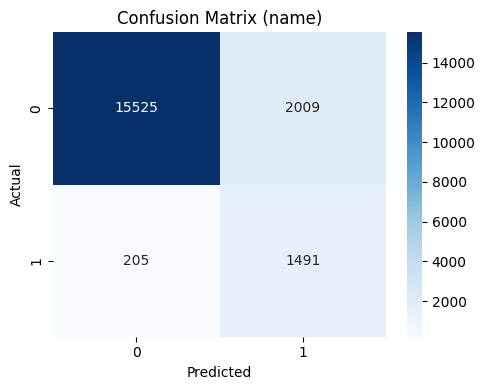


=== (name) ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



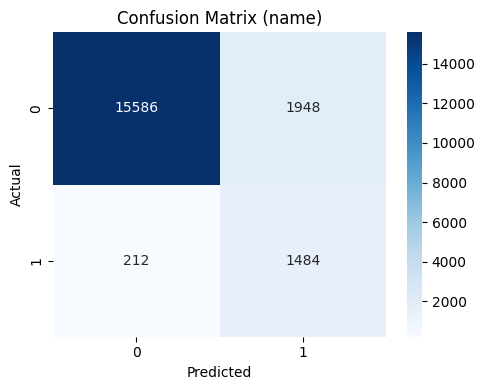


=== (name) ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



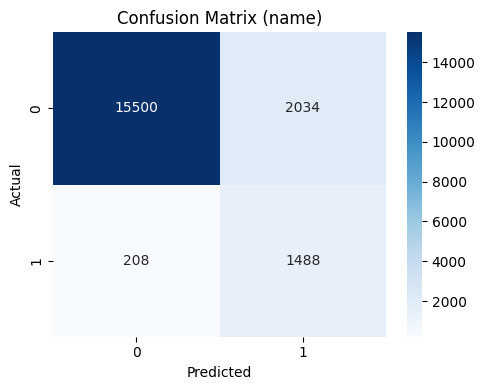

KeyboardInterrupt: 

In [ ]:
# Навчання на збалансованих даних, оцінювання на початковій тестовій вибірці
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    predictions=model.predict(X_test_scaled)
    print(f"\n=== (name) ===")
    print(classification_report(y_test, predictions, zero_division=0))
    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot = True, fmt='d', cmap= 'Blues')
    plt.title(f'Confusion Matrix (name)')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [ ]:
# Помірні сітки для обчислювально важкого SVC і 3-fold CV.
param_grids = {
    "LogisticRegression": {"model__C": [0.1, 1, 10], "model__solver": ["lbfgs"]},
    "RidgeClassifier": {"model__alpha": [0.1, 1.0, 10.0]},
    "SGDClassifier": {"model__loss": ["log_loss", "modified_huber"],
                      "model__penalty": ["l2", "l1"], "model__alpha": [0.0001, 0.001]},
    "SVC": {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"]},
}
print("Сітки гіперпараметрів підготовлені.")

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\nПідбір параметрів для {name}...")

    # У кожному CV-згині scaler і SMOTE навчаються тільки на відповідному train.
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    params = {'model__' + key: values for key, values in param_grids[name].items()}

    search = HalvingGridSearchCV(
        pipeline, params, scoring='f1', cv=3, factor=2,
        min_resources=300, random_state=42, n_jobs=1
    )

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print('Найкращі параметри:', search.best_params_)
    print(f'F1 на кросвалідації: {search.best_score_:.3f}')

    predictions = search.best_estimator_.predict(X_test)
    print('Класифікаційний звіт на test:')
    print(classification_report(y_test, predictions, zero_division=0))

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]
print("Найкраща модель за CV F1:", best_model_name)
print(f"Середній F1 на кросвалідації: {best_scores[best_model_name]:.4f}")
print("Зверніть увагу: модель обрана за CV, а не за test F1.")

In [ ]:
sample_indices = X_test.sample(n=min(10, len(X_test)), random_state=42).index
sample_predictions = best_model.predict(X_test.loc[sample_indices])
results_10 = pd.DataFrame({
    "індекс": sample_indices,
    "істинний клас": y_test.loc[sample_indices].to_numpy(),
    "передбачений клас": sample_predictions,
})
display(results_10.reset_index(drop=True))

**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?